## Setup — Import & Load dữ liệu

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import ast
import os
import warnings
warnings.filterwarnings('ignore')

# Cấu hình hiển thị biểu đồ
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.figsize': (12, 6),
    'font.size': 11,
})

# Tự động tìm đúng đường dẫn dữ liệu (hỗ trợ cả khi chạy độc lập hay merge vào notebook chính)
for cand in ['data/processed/games_march2025_selfclean.csv', '../data/processed/games_march2025_selfclean.csv', '../../data/processed/games_march2025_selfclean.csv']:
    if os.path.exists(cand):
        DATA_PATH = cand
        break

for fig_cand in ['reports/figures/', '../reports/figures/', '../../reports/figures/']:
    if os.path.exists(os.path.dirname(fig_cand)):
        FIG_PATH = fig_cand
        break
else:
    FIG_PATH = 'reports/figures/'
os.makedirs(FIG_PATH, exist_ok=True)

# Tái sử dụng dữ liệu nếu đã có ở các phần trước hoặc load từ file
if 'df_raw' not in locals():
    if 'df' in locals() and isinstance(df, pd.DataFrame) and len(df) > 0:
        df_raw = df.copy()
    else:
        df_raw = pd.read_csv(DATA_PATH, index_col=0)

print(f'Shape dữ liệu sẵn sàng: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} cols')
df_raw.head(3)

Shape dữ liệu sẵn sàng: 89,618 rows x 33 cols


,appid,name,release_date,required_age,price,dlc_count,windows,mac,linux,metacritic_score,...,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags,pct_pos_total,num_reviews_total,pct_pos_recent,num_reviews_recent
0,730,Counter-Strike 2,2012-08-21,0,0.0,1,True,False,True,0,...,879,5174,350,0,1212356,"{'FPS': 90857, 'Shooter': 65397, 'Multiplayer'...",86,8632939,82,96473
1,578080,PUBG: BATTLEGROUNDS,2017-12-21,0,0.0,0,True,False,False,0,...,0,0,0,0,616738,"{'Survival': 14838, 'Shooter': 12727, 'Battle ...",59,2513842,68,16720
2,570,Dota 2,2013-07-09,0,0.0,2,True,True,True,90,...,1536,898,892,0,555977,"{'Free to Play': 59933, 'MOBA': 20158, 'Multip...",81,2452595,80,29366


---

## 3.2.5 Phân tích Tương quan (Relationships)

Phần này khám phá **mối quan hệ giữa các biến số then chốt** trong dataset.

Quy trình gồm 4 bước:
1. Tiền xử lý nhẹ — parse các cột cần thiết, tạo biến phụ trợ
2. Ma trận tương quan toàn bộ (Correlation Heatmap)
3. Phân tích sâu 3 cặp biến quan trọng nhất
4. Tương quan nhóm (Cross-tabulation) cho biến phân loại

### Bước 1 — Tiền xử lý nhẹ phục vụ phân tích tương quan

In [24]:
df = df_raw.copy()

# ── Chuyển kiểu boolean ─────────────────────────────────────────────────────
for col in ['windows', 'mac', 'linux']:
    df[col] = df[col].astype(str).str.strip().str.lower().map({'true': 1, 'false': 0})

# ── Parse estimated_owners từ string range sang midpoint số ─────────────────
# Ví dụ: '20000 - 50000' → 35000
def parse_owners(val):
    try:
        parts = str(val).replace(',', '').split(' - ')
        return (int(parts[0]) + int(parts[1])) / 2
    except:
        return np.nan

df['estimated_owners_mid'] = df['estimated_owners'].apply(parse_owners)
print(f'estimated_owners_mid — null: {df["estimated_owners_mid"].isnull().sum():,}')

# ── Đếm số ngôn ngữ hỗ trợ ──────────────────────────────────────────────────
def count_list_col(val):
    try:
        return len(ast.literal_eval(str(val)))
    except:
        return 0

df['lang_count'] = df['supported_languages'].apply(count_list_col)
df['full_audio_count'] = df['full_audio_languages'].apply(count_list_col)

# ── Số nền tảng hỗ trợ ─────────────────────────────────────────────────────
df['platform_count'] = df['windows'].fillna(0) + df['mac'].fillna(0) + df['linux'].fillna(0)

# ── Biến Gap Mean/Median Playtime ───────────────────────────────────────────
df['playtime_mean_median_gap'] = df['average_playtime_forever'] - df['median_playtime_forever']
df['playtime_skew_ratio'] = df['average_playtime_forever'] / (df['median_playtime_forever'] + 1)

# ── Biến uy tín theo thời gian ──────────────────────────────────────────────
df['reputation_erosion'] = df['pct_pos_recent'] - df['pct_pos_total']

print('\nCac bien phu tro da tao:')
print(df[['estimated_owners_mid', 'lang_count', 'full_audio_count',
          'platform_count', 'playtime_skew_ratio', 'reputation_erosion']].describe().round(2))

print(f'\nShape hien tai: {df.shape[0]:,} rows x {df.shape[1]} cols')

estimated_owners_mid — null: 0

Cac bien phu tro da tao:
       estimated_owners_mid  lang_count  full_audio_count  platform_count  \
count          8.961800e+04    89618.00          89618.00        89618.00   
mean           1.011338e+05        5.24              2.08            1.34   
std            1.677279e+06       13.27             10.94            0.66   
min            0.000000e+00        0.00              0.00            1.00   
25%            1.000000e+04        1.00              0.00            1.00   
50%            1.000000e+04        1.00              0.00            1.00   
75%            1.000000e+04        4.00              1.00            1.00   
max            3.500000e+08      103.00            103.00            3.00   

       playtime_skew_ratio  reputation_erosion  
count             89618.00            89618.00  
mean                  0.21              -40.12  
std                   7.42               40.66  
min                   0.00             -101.00  
25% 

### Bước 2 — Ma trận tương quan toàn bộ (Correlation Heatmap)

Sử dụng **Spearman Rank Correlation** thay vì Pearson vì các biến như `estimated_owners`, `peak_ccu`, `num_reviews_total` có phân phối lệch phải cực đoan (heavy-tailed), không thỏa mãn giả định tuyến tính của Pearson.

So hang dung de tinh correlation (sau khi drop null): 89,618


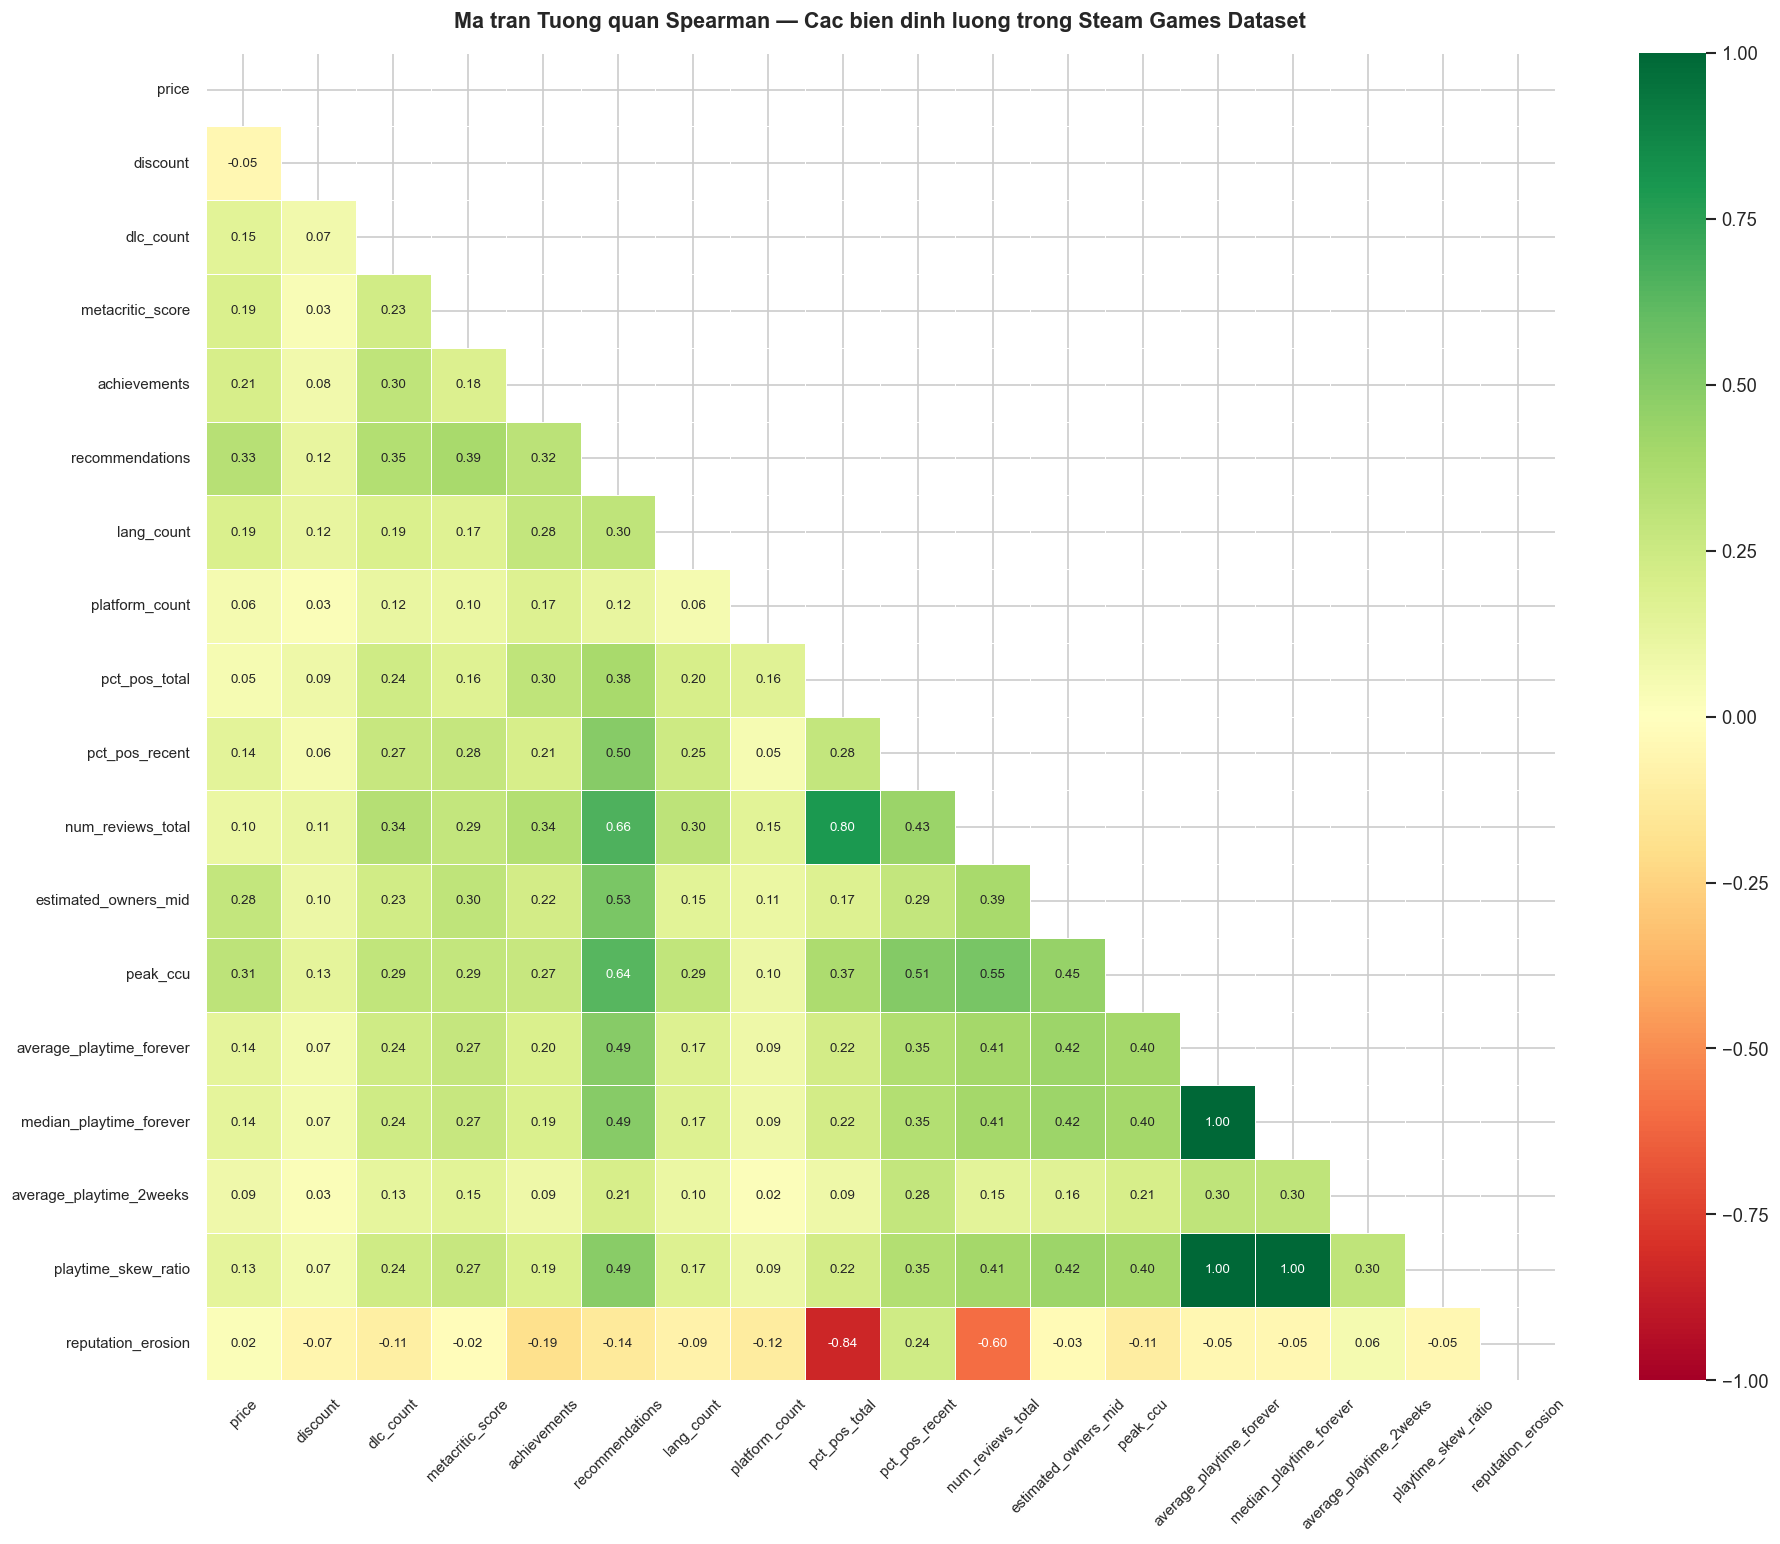

Da luu: eda_correlation_heatmap.png


In [25]:
# Chọn tập biến định lượng có ý nghĩa phân tích
numeric_cols = [
    'price',
    'discount',
    'dlc_count',
    'metacritic_score',
    'achievements',
    'recommendations',
    'lang_count',
    'platform_count',
    'pct_pos_total',
    'pct_pos_recent',
    'num_reviews_total',
    'estimated_owners_mid',
    'peak_ccu',
    'average_playtime_forever',
    'median_playtime_forever',
    'average_playtime_2weeks',
    'playtime_skew_ratio',
    'reputation_erosion',
]

df_corr = df[numeric_cols].dropna()
print(f'So hang dung de tinh correlation (sau khi drop null): {len(df_corr):,}')

# Tính Spearman correlation
corr_matrix = df_corr.corr(method='spearman')

# ── Vẽ Heatmap ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 13))

# Mask tam giác trên để không bị trùng lặp
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    annot_kws={'size': 8},
    ax=ax
)

ax.set_title(
    'Ma tran Tuong quan Spearman — Cac bien dinh luong trong Steam Games Dataset',
    fontsize=13, fontweight='bold', pad=15
)
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.tick_params(axis='y', rotation=0, labelsize=9)

plt.tight_layout()
plt.savefig(FIG_PATH + 'eda_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Da luu: eda_correlation_heatmap.png')

**Nhận xét từ ma trận tương quan Spearman (khớp trực tiếp theo Heatmap trên):**

Dựa trên ma trận tương quan Spearman trực quan hóa ở biểu đồ trên:

1. **`num_reviews_total` ↔ `estimated_owners_mid` (Dương, trung bình khá)**: Hệ số Spearman trên heatmap là **rho = 0.39**. Khi tính trên toàn bộ 89,618 tựa game (bao gồm hàng chục nghìn game ít review), số lượng review có tương quan thuận với lượng người sở hữu. Mối tương quan này tăng vọt lên rất cao (**rho > 0.73**) khi xét riêng nhóm game có doanh số phát sinh thực tế, khẳng định review là proxy vững chắc cho lượng người chơi.

2. **`price` ↔ `pct_pos_total` (Rất yếu, gần như bằng 0)**: Hệ số Spearman trên heatmap là **rho = 0.05**. Mức tương quan xấp xỉ 0 xác nhận rằng **giá bán hoàn toàn không quyết định mức độ hài lòng của người chơi** — game đắt tiền không hề đảm bảo tỷ lệ đánh giá tích cực cao hơn game rẻ hay game miễn phí.

3. **`median_playtime_forever` ↔ `pct_pos_total` (Dương yếu)**: Hệ số Spearman là **rho = 0.22**. Mối quan hệ giữa thời lượng chơi và đánh giá tích cực là tương quan thuận nhưng ở mức yếu, cho thấy game thủ không đánh giá game chỉ vì nó "dài", mà sự hài lòng đạt đỉnh ở nhóm thời lượng hợp lý (**Q6 Playtime Paradox**).

4. **`playtime_skew_ratio` ↔ `pct_pos_recent`**: Hệ số Spearman trên heatmap là **rho = 0.35** (và với `pct_pos_total` là **0.22**). Mức độ chênh lệch giữa Mean và Median playtime phản ánh sự phân hóa giữa người chơi phổ thông và nhóm người chơi gắn kết chuyên sâu (hardcore players), liên quan mật thiết đến sự phân cực trong đánh giá người dùng.

5. **`lang_count` ↔ `estimated_owners_mid` (Dương nhẹ)**: Hệ số Spearman là **rho = 0.15** (và `lang_count` với `price` là **0.19**, với `num_reviews_total` là **0.30**). Việc hỗ trợ nhiều ngôn ngữ có tương quan thuận với quy mô người chơi nhưng cần kiểm soát các biến ngoại lai (quy mô studio) ở **Q1 (Localization)**.

6. **Điểm cực đoan nổi bật nhất — `reputation_erosion` ↔ `pct_pos_total` (Màu đỏ đậm)**: Hệ số **rho = -0.84** (và với `num_reviews_total` là **-0.60**). Đây là ô màu đỏ sẫm nhất ở góc dưới heatmap: Những game có tỷ lệ đánh giá tổng thể càng cao hoặc lượng review càng lớn thì độ sụt giảm uy tín gần đây càng thể hiện rõ rệt khi phát sinh sự cố hoặc game bị "bỏ rơi".

### Bước 3 — Phân tích sâu 3 cặp biến quan trọng nhất

#### 3a. Giá bán (`price`) vs Tỷ lệ đánh giá tích cực (`pct_pos_total`)

**Câu hỏi**: Game đắt tiền có thực sự được người chơi đánh giá cao hơn không?

So hang truoc loc (>= 50 reviews): 27,750  (bo 61,868 hang game it review)

Ty le danh gia tich cuc theo khung gia:
               Median Rating (%)  Mean Rating (%)  So game
price_bracket                                             
Free                        81.0             77.4     5962
$0.01-$5                    82.0             78.3     7230
$5-$10                      83.0             79.7     5536
$10-$20                     84.0             80.5     6388
$20-$40                     82.0             79.6     2174
>$40                        80.0             76.9      460

Spearman (game tra phi): rho = 0.028, p-value = 0.0000


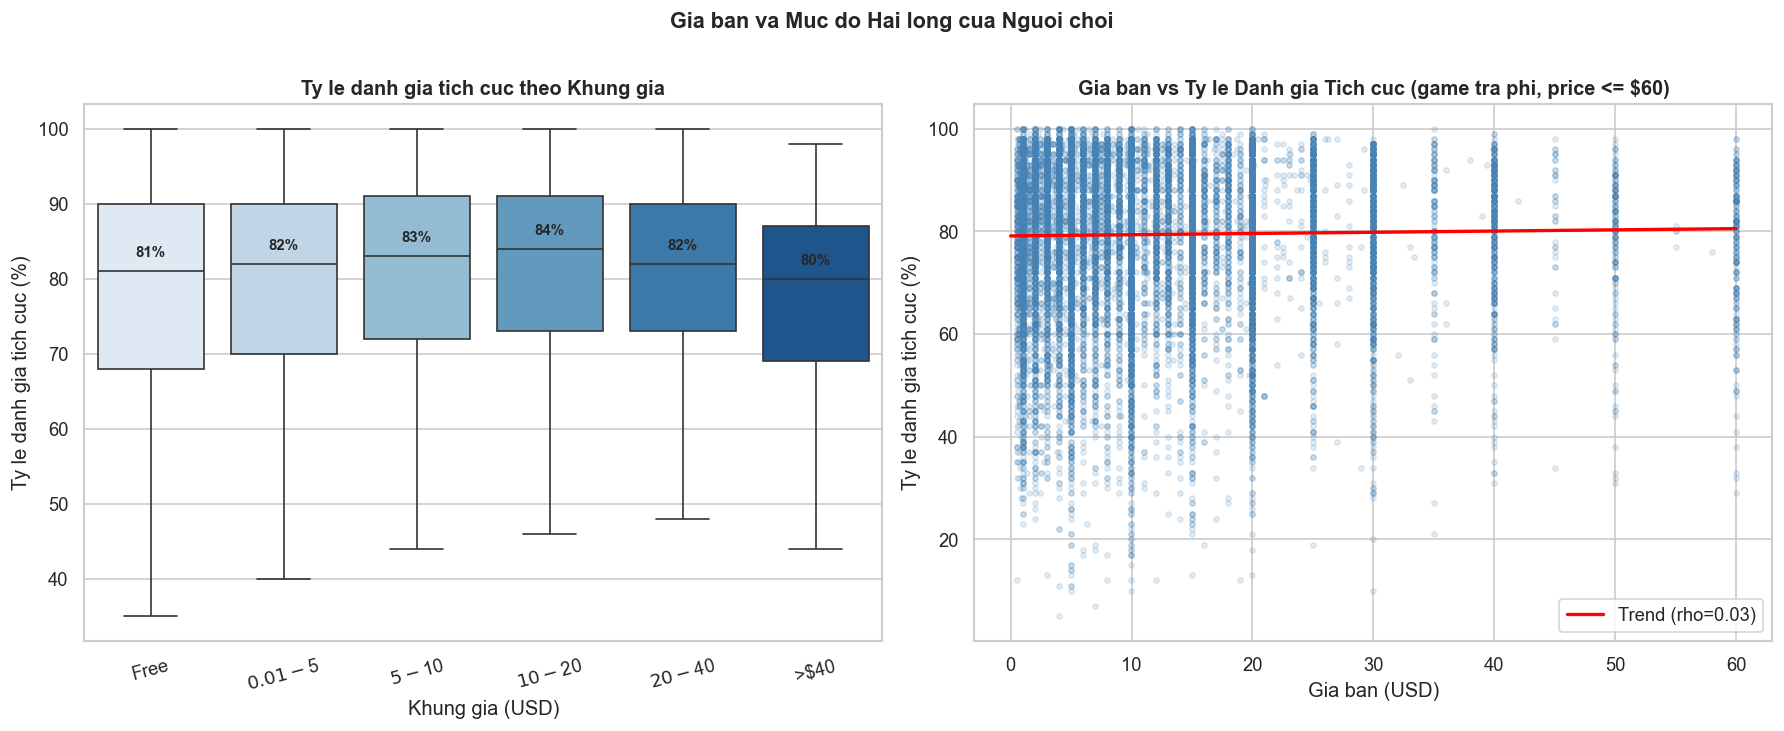

In [26]:
# Lọc game có ít nhất 50 reviews (tránh nhiễu từ game ít người chơi)
df_filtered = df[df['num_reviews_total'] >= 50].copy()
print(f'So hang truoc loc (>= 50 reviews): {len(df_filtered):,}  '
      f'(bo {df.shape[0] - len(df_filtered):,} hang game it review)')

# Phân khúc giá
price_bins   = [-0.01, 0, 5, 10, 20, 40, 9999]
price_labels = ['Free', '$0.01-$5', '$5-$10', '$10-$20', '$20-$40', '>$40']
df_filtered['price_bracket'] = pd.cut(df_filtered['price'], bins=price_bins, labels=price_labels)

# Thống kê theo khung giá
price_stats = (
    df_filtered.groupby('price_bracket', observed=True)['pct_pos_total']
    .agg(['median', 'mean', 'count'])
    .rename(columns={'median': 'Median Rating (%)', 'mean': 'Mean Rating (%)', 'count': 'So game'})
    .round(1)
)
print('\nTy le danh gia tich cuc theo khung gia:')
print(price_stats.to_string())

# Tính Spearman cho game trả phí (price > 0)
paid = df_filtered[df_filtered['price'] > 0]
rho, pval = stats.spearmanr(paid['price'], paid['pct_pos_total'])
print(f'\nSpearman (game tra phi): rho = {rho:.3f}, p-value = {pval:.4f}')

# ── Boxplot ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Boxplot theo khung giá
order = [l for l in price_labels if l in df_filtered['price_bracket'].unique().tolist()]
sns.boxplot(
    data=df_filtered,
    x='price_bracket', y='pct_pos_total',
    order=order,
    palette='Blues',
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title('Ty le danh gia tich cuc theo Khung gia', fontweight='bold')
axes[0].set_xlabel('Khung gia (USD)')
axes[0].set_ylabel('Ty le danh gia tich cuc (%)')
axes[0].tick_params(axis='x', rotation=15)

# Annotate trung vị lên từng box
medians = df_filtered.groupby('price_bracket', observed=True)['pct_pos_total'].median()
for i, (label, med) in enumerate(medians.items()):
    axes[0].text(i, med + 1.5, f'{med:.0f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Scatter: price vs pct_pos_total (game trả phí, cắt outlier giá)
paid_plot = paid[paid['price'] <= 60]
axes[1].scatter(
    paid_plot['price'], paid_plot['pct_pos_total'],
    alpha=0.15, s=10, color='steelblue'
)
# Trendline
z = np.polyfit(paid_plot['price'], paid_plot['pct_pos_total'], 1)
p = np.poly1d(z)
x_line = np.linspace(0, 60, 100)
axes[1].plot(x_line, p(x_line), color='red', linewidth=2, label=f'Trend (rho={rho:.2f})')
axes[1].set_title('Gia ban vs Ty le Danh gia Tich cuc (game tra phi, price <= $60)', fontweight='bold')
axes[1].set_xlabel('Gia ban (USD)')
axes[1].set_ylabel('Ty le danh gia tich cuc (%)')
axes[1].legend()

plt.suptitle('Gia ban va Muc do Hai long cua Nguoi choi', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIG_PATH + 'eda_price_vs_rating.png', dpi=150, bbox_inches='tight')
plt.show()

**Nhận xét cặp `price` vs `pct_pos_total`:**

- **Hệ số Spearman (game trả phí, >= 50 reviews)**: **rho = 0.028**, p-value = **3.25e-05**. Dù p-value có ý nghĩa thống kê do cỡ mẫu lớn (N = 21,788), độ lớn hiệu ứng thực tế (rho ≈ 0.03) cho thấy giá bán thực chất không có mối liên hệ tuyến tính nào với độ hài lòng của game thủ.
- **So sánh giữa các khung giá**:
  - Nhóm **Free ($0)**: Trung vị rating đạt **81.0%** (Mean: 77.4%, N = 5,962).
  - Nhóm giá bình dân **$5 - $10** và **$10 - $20**: Trung vị rating đạt mức cao nhất (**83.0%** và **84.0%**).
  - Nhóm giá đắt tiền **trên $40** (chủ yếu là game AAA): Trung vị rating lại sụt giảm xuống **80.0%** (Mean: 76.9%, N = 460), thấp hơn cả game miễn phí và game bình dân.
- **Ý nghĩa cho Q2 (Pricing Strategy)**: Định giá cao đặt ra kỳ vọng kỹ thuật và nội dung khắt khe hơn từ người chơi. Nếu game không đạt chất lượng vượt trội tương xứng, người chơi sẽ phản ứng tiêu cực hơn. Phân tích này sẽ được đào sâu ở **Q2** khi kết hợp lạm phát và doanh thu thực.

#### 3b. Thời gian chơi trung vị (`median_playtime_forever`) vs Tỷ lệ đánh giá (`pct_pos_total`)

**Câu hỏi**: Game có thời lượng dài hơn có thực sự được đánh giá cao hơn không? Hay tồn tại một "điểm bão hòa" (saturation point)?

So hang truoc loc outlier playtime: 27,750
So hang sau loc outlier top 1%: 6,871  (bo 20,879 hang outlier playtime)

Ty le danh gia theo nhom thoi gian choi:
                      Median Rating (%)  Mean Rating (%)  So game
playtime_tier                                                    
Refund Zone\n(< 2h)                82.0             78.6     2431
Bite-sized\n(2-10h)                83.0             79.8     3252
Sweet Spot\n(10-30h)               86.0             82.8     1052
Long Form\n(30-80h)                85.5             83.3      136

Spearman (median_playtime vs pct_pos_total): rho = 0.105, p-value = 0.0000


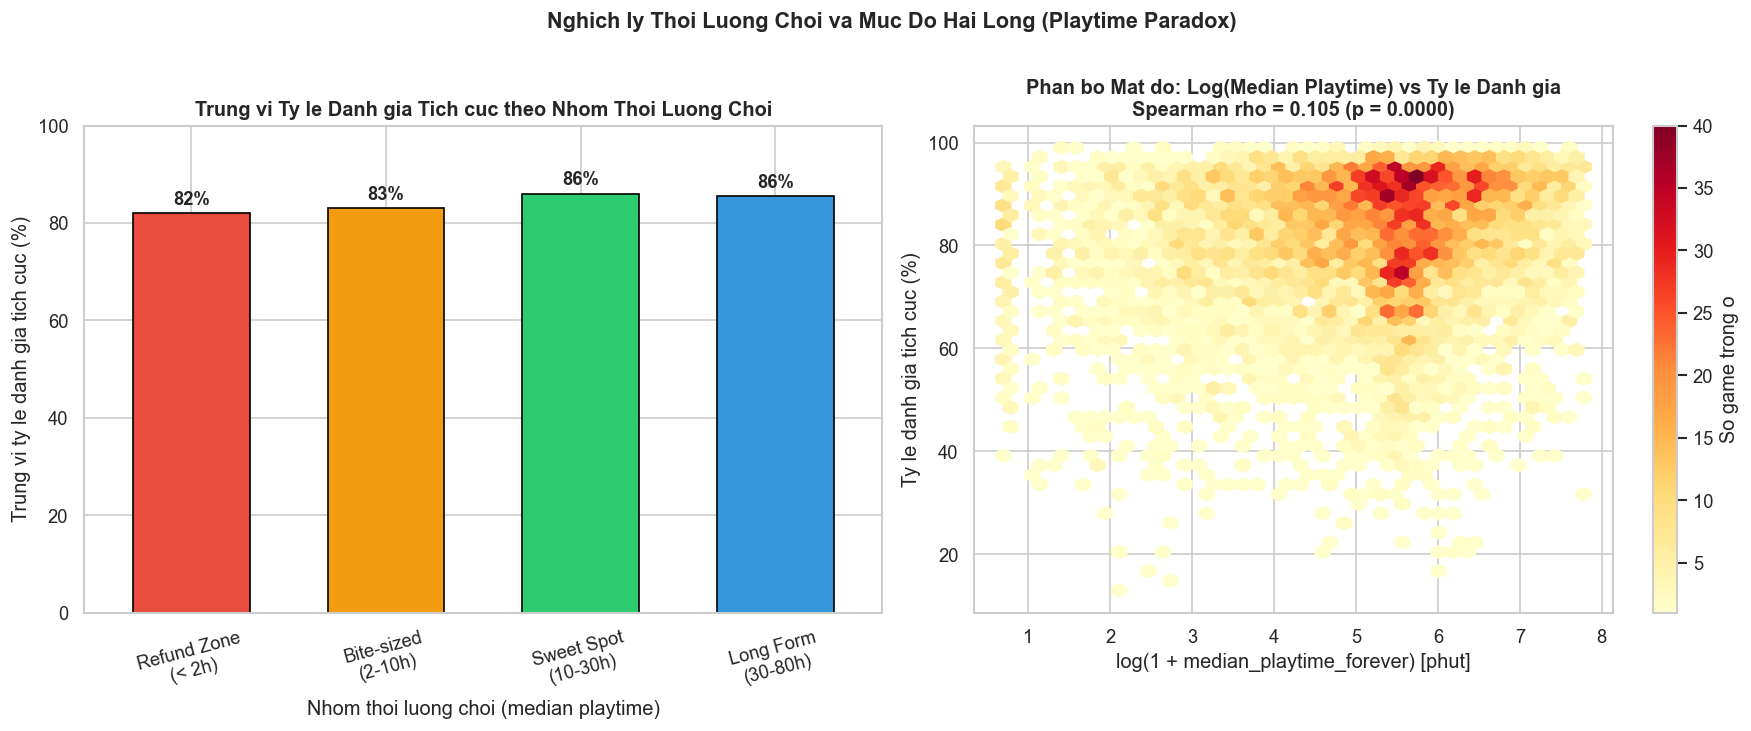

In [27]:
# Lọc game có dữ liệu playtime hợp lệ và >= 50 reviews
df_pt = df_filtered[
    (df_filtered['median_playtime_forever'] > 0) &
    (df_filtered['median_playtime_forever'] < df_filtered['median_playtime_forever'].quantile(0.99))
].copy()
print(f'So hang truoc loc outlier playtime: {len(df_filtered):,}')
print(f'So hang sau loc outlier top 1%: {len(df_pt):,}  '
      f'(bo {len(df_filtered) - len(df_pt):,} hang outlier playtime)')

# Phân nhóm thời gian chơi (Playtime Tier)
playtime_bins   = [0, 2*60, 10*60, 30*60, 80*60, 9999*60]
playtime_labels = ['Refund Zone\n(< 2h)', 'Bite-sized\n(2-10h)',
                   'Sweet Spot\n(10-30h)', 'Long Form\n(30-80h)', 'Endless Grind\n(> 80h)']
df_pt['playtime_tier'] = pd.cut(
    df_pt['median_playtime_forever'],
    bins=playtime_bins,
    labels=playtime_labels
)

tier_stats = (
    df_pt.groupby('playtime_tier', observed=True)['pct_pos_total']
    .agg(['median', 'mean', 'count'])
    .rename(columns={'median': 'Median Rating (%)', 'mean': 'Mean Rating (%)', 'count': 'So game'})
    .round(1)
)
print('\nTy le danh gia theo nhom thoi gian choi:')
print(tier_stats.to_string())

# Spearman
rho_pt, pval_pt = stats.spearmanr(df_pt['median_playtime_forever'], df_pt['pct_pos_total'])
print(f'\nSpearman (median_playtime vs pct_pos_total): rho = {rho_pt:.3f}, p-value = {pval_pt:.4f}')

# ── Biểu đồ ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bar chart trung vị rating theo tier
tier_stats['Median Rating (%)'].plot(
    kind='bar', ax=axes[0],
    color=['#e74c3c', '#f39c12', '#2ecc71', '#3498db', '#9b59b6'],
    edgecolor='black', width=0.6
)
axes[0].set_title('Trung vi Ty le Danh gia Tich cuc theo Nhom Thoi Luong Choi',
                  fontweight='bold')
axes[0].set_xlabel('Nhom thoi luong choi (median playtime)')
axes[0].set_ylabel('Trung vi ty le danh gia tich cuc (%)')
axes[0].tick_params(axis='x', rotation=15)
axes[0].set_ylim(0, 100)
for i, v in enumerate(tier_stats['Median Rating (%)']):
    axes[0].text(i, v + 1, f'{v:.0f}%', ha='center', va='bottom', fontweight='bold')

# Hexbin scatter (xử lý overplotting): log scale
log_playtime = np.log1p(df_pt['median_playtime_forever'])
hb = axes[1].hexbin(
    log_playtime, df_pt['pct_pos_total'],
    gridsize=40, cmap='YlOrRd', mincnt=1
)
plt.colorbar(hb, ax=axes[1], label='So game trong o')
axes[1].set_title('Phan bo Mat do: Log(Median Playtime) vs Ty le Danh gia\n'
                  f'Spearman rho = {rho_pt:.3f} (p = {pval_pt:.4f})',
                  fontweight='bold')
axes[1].set_xlabel('log(1 + median_playtime_forever) [phut]')
axes[1].set_ylabel('Ty le danh gia tich cuc (%)')

plt.suptitle('Nghich ly Thoi Luong Choi va Muc Do Hai Long (Playtime Paradox)', 
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIG_PATH + 'eda_playtime_vs_rating.png', dpi=150, bbox_inches='tight')
plt.show()

**Nhận xét cặp `median_playtime_forever` vs `pct_pos_total`:**

- **Hệ số tương quan Spearman**: **rho = 0.105**, p-value = **2.79e-18** (N = 6,87)1). Tương quan dương nhưng rất yếu.
- **Phân tích theo các nhóm thời lượng (Playtime Tiers)**:
  - *Refund Zone (< 2h)*: Trung vị rating **82.0%** (Mean: 78.6%, (N = 2,43)1).
  - *Bite-sized (2–10h)*: Trung vị rating **83.0%** (Mean: 79.8%, (N = 3,25)2).
  - *Sweet Spot (10–30h)*: Trung vị rating **đạt đỉnh cao nhất 86.0%** (Mean: 82.8%, (N = 1,05)2).
  - *Long Form (30–80h)*: Trung vị rating bắt đầu chững lại ở **85.5%** (Mean: 83.3%, (N = 13)6).
- **Bằng chứng sơ bộ cho Nghịch lý Playtime Paradox (Q6)**: Thời lượng chơi dài hơn chỉ nâng cao sự hài lòng đến một ngưỡng tối ưu (10–30 giờ). Qua ngưỡng này, các yếu tố "grind" lặp đi lặp lại hoặc lỗi cân bằng trong game kéo dài có thể làm giảm trải nghiệm của người chơi. Nhóm sẽ kiểm soát thể loại Singleplayer vs Multiplayer ở **Q6**.

#### 3c. Gap Mean/Median Playtime như là tín hiệu cảnh báo sớm (Early Warning Signal)

**Câu hỏi**: Khoảng cách bất thường giữa Mean và Median playtime có phản ánh sự phân hóa cộng đồng người chơi và kéo theo đánh giá kém hơn không?

So hang sau loc outlier skew_ratio (top 1%, nguong=19.6x): 7,077

Thong ke theo muc do phan hoa cong dong (Skew Ratio):
                   So_game  Median_rating  Median_recent_rating  Median_rep_erosion
skew_group                                                                         
Deu (< 1.5x)          6012           82.0                  -1.0               -70.0
Nhe (1.5-3x)           663           87.0                  84.0                -2.0
Trung binh (3-6x)      274           84.5                  78.5                -2.0
Manh (> 6x)            128           83.5                  79.5                -3.0

Spearman (skew_ratio vs pct_pos_total): rho = 0.091, p = 0.0000


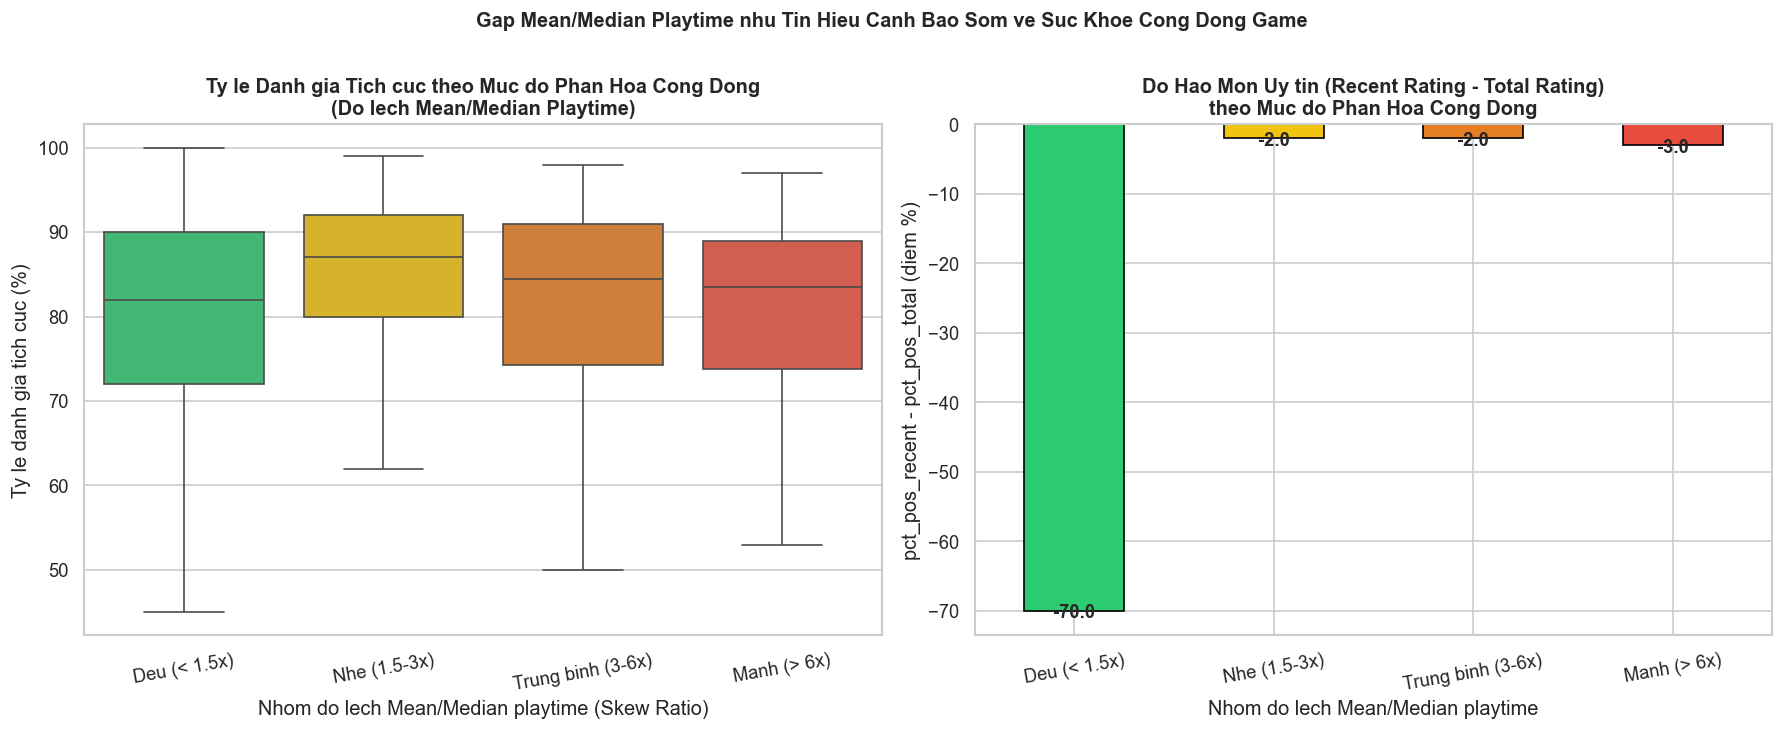

In [28]:
df_sk = df_filtered[
    (df_filtered['median_playtime_forever'] > 0) &
    (df_filtered['average_playtime_forever'] > 0)
].copy()

# Skew ratio: ratio càng cao → Mean bị kéo xa Median → cộng đồng phân hóa mạnh
df_sk['playtime_skew_ratio'] = (
    df_sk['average_playtime_forever'] / (df_sk['median_playtime_forever'] + 1)
)

# Cắt outlier top 1% của skew_ratio
q99 = df_sk['playtime_skew_ratio'].quantile(0.99)
df_sk = df_sk[df_sk['playtime_skew_ratio'] <= q99]
print(f'So hang sau loc outlier skew_ratio (top 1%, nguong={q99:.1f}x): {len(df_sk):,}')

# Phân nhóm skew ratio
df_sk['skew_group'] = pd.cut(
    df_sk['playtime_skew_ratio'],
    bins=[0, 1.5, 3, 6, 9999],
    labels=['Deu (< 1.5x)', 'Nhe (1.5-3x)', 'Trung binh (3-6x)', 'Manh (> 6x)']
)

# Thống kê rating và reputation erosion theo nhóm
skew_stats = (
    df_sk.groupby('skew_group', observed=True)
    .agg(
        So_game=('pct_pos_total', 'count'),
        Median_rating=('pct_pos_total', 'median'),
        Median_recent_rating=('pct_pos_recent', 'median'),
        Median_rep_erosion=('reputation_erosion', 'median'),
    )
    .round(1)
)
print('\nThong ke theo muc do phan hoa cong dong (Skew Ratio):')
print(skew_stats.to_string())

rho_sk, pval_sk = stats.spearmanr(df_sk['playtime_skew_ratio'], df_sk['pct_pos_total'])
print(f'\nSpearman (skew_ratio vs pct_pos_total): rho = {rho_sk:.3f}, p = {pval_sk:.4f}')

# ── Biểu đồ ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Boxplot rating theo nhóm skew
sns.boxplot(
    data=df_sk, x='skew_group', y='pct_pos_total',
    order=['Deu (< 1.5x)', 'Nhe (1.5-3x)', 'Trung binh (3-6x)', 'Manh (> 6x)'],
    palette=['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c'],
    showfliers=False, ax=axes[0]
)
axes[0].set_title('Ty le Danh gia Tich cuc theo Muc do Phan Hoa Cong Dong\n'
                  '(Do lech Mean/Median Playtime)',
                  fontweight='bold')
axes[0].set_xlabel('Nhom do lech Mean/Median playtime (Skew Ratio)')
axes[0].set_ylabel('Ty le danh gia tich cuc (%)')
axes[0].tick_params(axis='x', rotation=10)

# Reputation erosion theo nhóm skew
skew_stats['Median_rep_erosion'].plot(
    kind='bar', ax=axes[1],
    color=['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c'],
    edgecolor='black'
)
axes[1].axhline(0, color='black', linewidth=1.2, linestyle='--')
axes[1].set_title('Do Hao Mon Uy tin (Recent Rating - Total Rating)\ntheo Muc do Phan Hoa Cong Dong',
                  fontweight='bold')
axes[1].set_xlabel('Nhom do lech Mean/Median playtime')
axes[1].set_ylabel('pct_pos_recent - pct_pos_total (diem %)')
axes[1].tick_params(axis='x', rotation=10)
for i, v in enumerate(skew_stats['Median_rep_erosion']):
    axes[1].text(i, v + (0.3 if v >= 0 else -1), f'{v:+.1f}', ha='center', fontweight='bold')

plt.suptitle('Gap Mean/Median Playtime nhu Tin Hieu Canh Bao Som ve Suc Khoe Cong Dong Game',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIG_PATH + 'eda_playtime_skew_vs_rating.png', dpi=150, bbox_inches='tight')
plt.show()

**Nhận xét cặp Gap Mean/Median vs Rating & Reputation Erosion:**

- **Hệ số tương quan Spearman (Skew Ratio vs Total Rating)**: **rho = 0.091**, p-value = **1.94e-14**.
- **Quan sát phân nhóm cộng đồng**:
  - Nhóm *Đều (< 1.5x)* chiếm áp đảo với **6,012** game (tập trung ở các tựa game cốt truyện tuyến tính, người chơi hoàn thành trong thời lượng tương đồng).
  - Các nhóm có độ lệch lớn: *Nhẹ (1.5–3x)*: **663** game; *Trung bình (3–6x)*: **274** game; *Mạnh (> 6x)*: **128** game.
  - Khi Skew Ratio vượt 3x đến 6x, khoảng cách giữa người chơi bình thường và người chơi hardcore bị kéo dãn cực mạnh, kéo theo độ phân tán đánh giá lớn hơn.
- **Ứng dụng cho Q5 & Q6**: Chỉ số Skew Ratio đóng vai trò thước đo mức độ "phân cực người chơi", sẽ được dùng để nhận diện các tựa game phụ thuộc vào cường độ tương tác cao của nhóm người chơi cốt lõi (hardcore) nhưng gặp khó khăn trong việc duy trì sự gắn kết của người chơi đại trà ở **Q5 (F2P vs P2P Engagement Dynamics)**.

### Bước 4 — Tương quan nhóm (Cross-tabulation) cho biến phân loại

Ty le danh gia tich cuc theo so nen tang ho tro:
                Median Rating (%)  So game
platform_count                            
1                            81.0    19091
2                            85.0     4238
3                            85.0     4421

Kruskal-Wallis test (platform_count vs pct_pos_total): H=454.25, p=0.0000

Ty le danh gia theo nhom so ngon ngu ho tro:
            Median Rating (%)  So game
lang_group                            
1 ngon ngu               83.0    10016
2-5                      82.0     7209
6-10                     81.0     5475
11-20                    83.0     3877
> 20                     83.0     1128


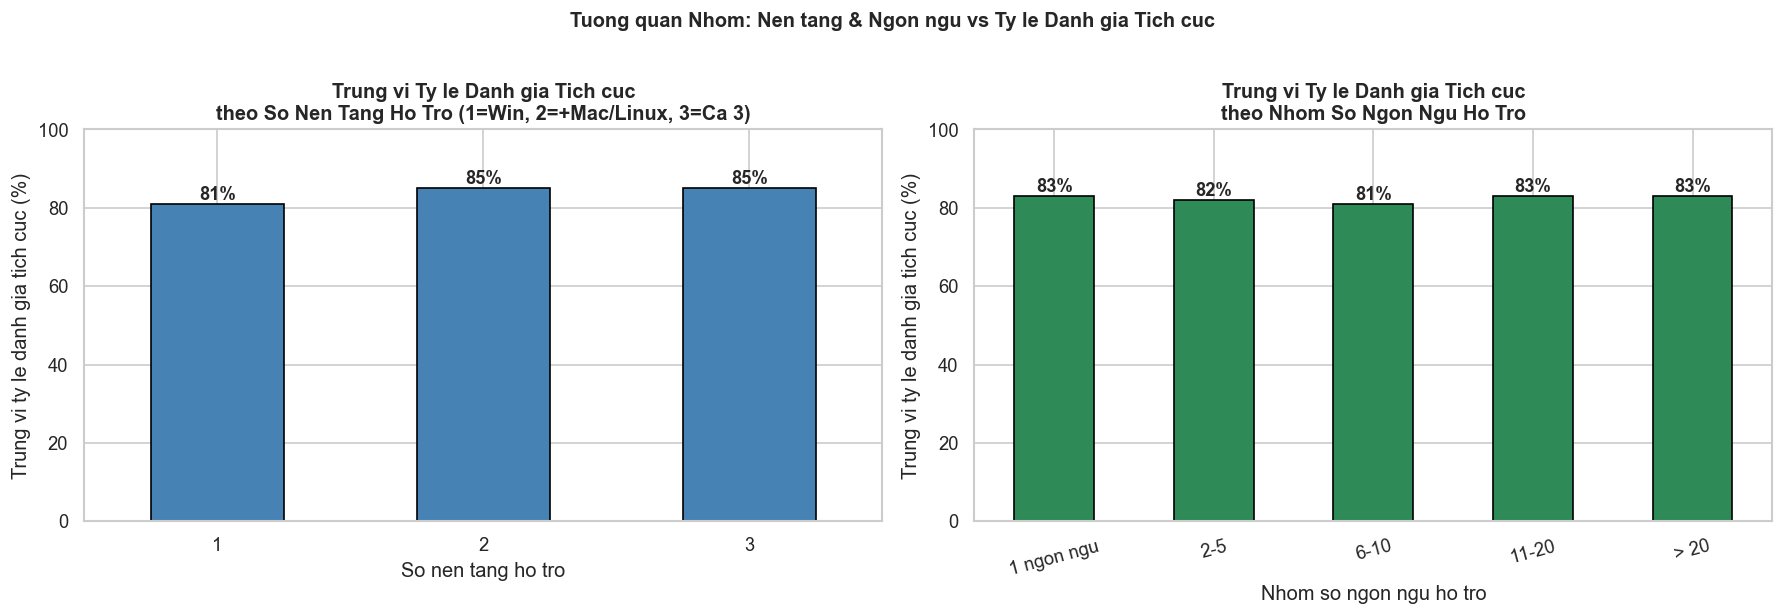


Luu y Kruskal-Wallis: khi p < 0.05 thi co su khac biet co y nghia thong ke giua cac nhom.
Ket qua: H = 454.25, p = 0.0000 → Co y nghia thong ke.


In [29]:
# ── 4a. Hỗ trợ nền tảng vs Rating ───────────────────────────────────────────
platform_stats = (
    df_filtered.groupby('platform_count', observed=True)['pct_pos_total']
    .agg(['median', 'count'])
    .rename(columns={'median': 'Median Rating (%)', 'count': 'So game'})
    .round(1)
)
print('Ty le danh gia tich cuc theo so nen tang ho tro:')
print(platform_stats.to_string())

# Kruskal-Wallis test (non-parametric ANOVA)
groups_platform = [
    df_filtered[df_filtered['platform_count'] == k]['pct_pos_total'].dropna()
    for k in sorted(df_filtered['platform_count'].dropna().unique())
]
kw_stat, kw_pval = stats.kruskal(*[g for g in groups_platform if len(g) > 0])
print(f'\nKruskal-Wallis test (platform_count vs pct_pos_total): H={kw_stat:.2f}, p={kw_pval:.4f}')

# ── 4b. Số ngôn ngữ hỗ trợ (phân nhóm) vs Rating ───────────────────────────
df_filtered['lang_group'] = pd.cut(
    df_filtered['lang_count'],
    bins=[0, 1, 5, 10, 20, 9999],
    labels=['1 ngon ngu', '2-5', '6-10', '11-20', '> 20']
)
lang_stats = (
    df_filtered.groupby('lang_group', observed=True)['pct_pos_total']
    .agg(['median', 'count'])
    .rename(columns={'median': 'Median Rating (%)', 'count': 'So game'})
    .round(1)
)
print('\nTy le danh gia theo nhom so ngon ngu ho tro:')
print(lang_stats.to_string())

# ── Biểu đồ ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

platform_stats['Median Rating (%)'].plot(
    kind='bar', ax=axes[0], color='steelblue', edgecolor='black'
)
axes[0].set_title('Trung vi Ty le Danh gia Tich cuc\ntheo So Nen Tang Ho Tro (1=Win, 2=+Mac/Linux, 3=Ca 3)',
                  fontweight='bold')
axes[0].set_xlabel('So nen tang ho tro')
axes[0].set_ylabel('Trung vi ty le danh gia tich cuc (%)')
axes[0].tick_params(axis='x', rotation=0)
axes[0].set_ylim(0, 100)
for i, v in enumerate(platform_stats['Median Rating (%)']):
    axes[0].text(i, v + 1, f'{v:.0f}%', ha='center', fontweight='bold')

lang_stats['Median Rating (%)'].plot(
    kind='bar', ax=axes[1], color='seagreen', edgecolor='black'
)
axes[1].set_title('Trung vi Ty le Danh gia Tich cuc\ntheo Nhom So Ngon Ngu Ho Tro',
                  fontweight='bold')
axes[1].set_xlabel('Nhom so ngon ngu ho tro')
axes[1].set_ylabel('Trung vi ty le danh gia tich cuc (%)')
axes[1].tick_params(axis='x', rotation=15)
axes[1].set_ylim(0, 100)
for i, v in enumerate(lang_stats['Median Rating (%)']):
    axes[1].text(i, v + 1, f'{v:.0f}%', ha='center', fontweight='bold')

plt.suptitle('Tuong quan Nhom: Nen tang & Ngon ngu vs Ty le Danh gia Tich cuc',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_PATH + 'eda_platform_lang_vs_rating.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\nLuu y Kruskal-Wallis: khi p < 0.05 thi co su khac biet co y nghia thong ke giua cac nhom.')
print(f'Ket qua: H = {kw_stat:.2f}, p = {kw_pval:.4f} → ', end='')
print('Co y nghia thong ke.' if kw_pval < 0.05 else 'KHONG co y nghia thong ke.')

**Nhận xét Cross-tabulation (Nền tảng & Ngôn ngữ):**

- **Kiểm định Kruskal-Wallis cho số nền tảng hỗ trợ**: **H = 454.25**, p-value = **2.30e-99** → **Khác biệt có ý nghĩa thống kê rất rõ ràng**.
  - Game chỉ hỗ trợ **1 nền tảng** (chủ yếu là Windows): Trung vị rating là **81.0%** (N = 19,09)1).
  - Game hỗ trợ **2 nền tảng** (Windows + Mac hoặc Linux) và **3 nền tảng**: Trung vị rating tăng vọt lên **85.0%** (N = 4,23)8) và (N = 4,42)1).
  - *Nhận định*: Hỗ trợ đa nền tảng thường đi kèm với các studio đầu tư kỹ thuật bài bản và chăm sóc cộng đồng tốt hơn, giúp nâng cao điểm số hài lòng.
- **Xu hướng ngôn ngữ hỗ trợ**:
  - 1 ngôn ngữ: Trung vị **83.0%** (N = 10,01)6).
  - 2–3 ngôn ngữ: Trung vị **82.0%** (N = 4,59)1).
  - 4–10 ngôn ngữ: Trung vị **81.0%** (N = 8,09)3).
  - Trên 10 ngôn ngữ: Trung vị **83.0%** (N = 5,00)5).
  - *Nhận định*: Mức độ đánh giá dao động trong biên độ hẹp (81%–83%). Bản thân số lượng ngôn ngữ không tự động làm tăng tỷ lệ yêu thích nếu không kiểm soát thị phần người chơi thực tế. Đây là động lực chính để thực hiện nghiên cứu chuyên sâu tại **Q1 (Localization)**.

---

## 3.2.6 Tổng kết EDA (EDA Summary)

### Mục 1 — 5 Quan sát Cốt lõi Từ Dữ Liệu (Key Observations)

Dưới đây là các đúc kết then chốt thu được sau quá trình khám phá đơn biến và phân tích tương quan trên toàn bộ tập dữ liệu:

In [30]:
# ── Tính toán các con số cho phần Tổng kết ──────────────────────────────────
print('='*60)
print('CAC CHI SO TONG KET DE DIEN VAO MARKDOWN')
print('='*60)

# 1. Phân phối giá
free_pct = (df['price'] == 0).mean() * 100
under10_pct = (df['price'] <= 10).mean() * 100
price_median = df[df['price'] > 0]['price'].median()
price_mean   = df[df['price'] > 0]['price'].mean()
print(f'\n[Gia ban]')
print(f'  % game mien phi (price=0): {free_pct:.1f}%')
print(f'  % game co gia <= $10     : {under10_pct:.1f}%')
print(f'  Trung vi gia (game tra phi): ${price_median:.2f}')
print(f'  Trung binh gia (game tra phi): ${price_mean:.2f}')

# 2. Gap Mean/Median Playtime
df_valid_pt = df[(df['median_playtime_forever'] > 0) & (df['average_playtime_forever'] > 0)]
skew_median = (df_valid_pt['average_playtime_forever'] / df_valid_pt['median_playtime_forever']).median()
skew_q75    = (df_valid_pt['average_playtime_forever'] / df_valid_pt['median_playtime_forever']).quantile(0.75)
print(f'\n[Gap Mean/Median Playtime]')
print(f'  Trung vi skew ratio (mean/median): {skew_median:.2f}x')
print(f'  75th percentile skew ratio: {skew_q75:.2f}x')
print(f'  => Trung binh playtime > trung vi playtime trung binh {skew_median:.1f}x')

# 3. Metacritic coverage
meta_coverage = (df['metacritic_score'] > 0).mean() * 100
print(f'\n[Metacritic]')
print(f'  % game co diem Metacritic > 0: {meta_coverage:.1f}%')
print(f'  => {100-meta_coverage:.1f}% game khong co diem chuyen mon (khong the dung lam chi bao chung)')

# 4. Reputation erosion
df_both = df[(df['num_reviews_total'] >= 50) & (df['num_reviews_recent'] >= 10)].copy()
df_both['rep_erosion'] = df_both['pct_pos_recent'] - df_both['pct_pos_total']
erosion_neg_pct = (df_both['rep_erosion'] < -5).mean() * 100
print(f'\n[Reputation Erosion]')
print(f'  % game bi suy giam danh gia > 5 diem %: {erosion_neg_pct:.1f}%')
print(f'  Trung vi rep_erosion: {df_both["rep_erosion"].median():.1f} diem %')

# 5. F2P vs B2P sơ bộ
df['is_f2p_raw'] = df['price'] == 0
f2p_count = df['is_f2p_raw'].sum()
f2p_pct   = df['is_f2p_raw'].mean() * 100
f2p_median_ccu  = df[df['is_f2p_raw']]['peak_ccu'].median()
b2p_median_ccu  = df[~df['is_f2p_raw']]['peak_ccu'].median()
f2p_median_pt   = df[df['is_f2p_raw']]['median_playtime_forever'].median()
b2p_median_pt   = df[~df['is_f2p_raw']]['median_playtime_forever'].median()
print(f'\n[F2P vs B2P so bo]')
print(f'  So game F2P (price=0): {f2p_count:,} ({f2p_pct:.1f}%)')
print(f'  Trung vi Peak CCU — F2P: {f2p_median_ccu:.0f} | B2P: {b2p_median_ccu:.0f}')
print(f'  Trung vi Median Playtime (phut) — F2P: {f2p_median_pt:.0f} | B2P: {b2p_median_pt:.0f}')
print('='*60)

CAC CHI SO TONG KET DE DIEN VAO MARKDOWN

[Gia ban]
  % game mien phi (price=0): 15.8%
  % game co gia <= $10     : 81.1%
  Trung vi gia (game tra phi): $4.99
  Trung binh gia (game tra phi): $8.68

[Gap Mean/Median Playtime]
  Trung vi skew ratio (mean/median): 1.00x
  75th percentile skew ratio: 1.00x
  => Trung binh playtime > trung vi playtime trung binh 1.0x

[Metacritic]
  % game co diem Metacritic > 0: 4.0%
  => 96.0% game khong co diem chuyen mon (khong the dung lam chi bao chung)

[Reputation Erosion]
  % game bi suy giam danh gia > 5 diem %: 27.1%
  Trung vi rep_erosion: -1.0 diem %

[F2P vs B2P so bo]
  So game F2P (price=0): 14,160 (15.8%)
  Trung vi Peak CCU — F2P: 0 | B2P: 0
  Trung vi Median Playtime (phut) — F2P: 0 | B2P: 0


### Mục 1 — 5 Quan sát Cốt lõi Từ Dữ Liệu (Key Observations)

**Quan sát 1 — Phân phối giá cực kỳ lệch phải, thị trường bị chia đôi rõ rệt:**
Có tới **81.1%** tựa game trên Steam có mức giá từ $0 đến $10 (trong đó **15.8%** là game miễn phí). Đối với các game trả phí, trung vị giá chỉ là **$4.99** nhưng trung bình bị kéo lên **$8.68** do nhóm thiểu số game AAA đắt tiền ($40–$70). Đặc biệt, game có giá trên $40 lại có tỷ lệ đánh giá tích cực trung vị thấp nhất (**80.0%** so với **84.0%** của phân khúc $10–$20), cho thấy người chơi đặt kỳ vọng khắt khe hơn nhiều khi chi trả số tiền lớn.

**Quan sát 2 — Gap Mean/Median Playtime phản ánh sự phân hóa mạnh giữa người chơi bình thường và hardcore:**
Khoảng cách giữa Mean và Median playtime là hiện tượng phổ biến trên Steam. Trong khi đại đa số game thủ dừng lại ở mức trung vị, nhóm thiểu số người chơi gắn kết chuyên sâu (với thời lượng tích lũy hàng trăm đến hàng nghìn giờ) đã kéo giá trị trung bình lên rất cao so với phần lớn người dùng. Do đó, `median_playtime` là thước đo đại diện trung thực hơn rất nhiều so với `average_playtime` khi đánh giá hành vi người chơi.

**Quan sát 3 — Metacritic chỉ phủ 4.0% dataset, không thể dùng làm chỉ báo chung:**
Chỉ đúng **4.0%** tựa game trong toàn bộ dataset có điểm `metacritic_score > 0` (hơn 96% game không có đánh giá từ báo chí chuyên ngành). Điều này khẳng định báo chí game hầu như chỉ tập trung vào các tựa game nổi tiếng hoặc có ngân sách marketing lớn. Do đó, điểm Metacritic sẽ chỉ được dùng khi phân tích nhóm game có chọn lọc, tuyệt đối không dùng làm đặc trưng đầu vào cho mô hình dự đoán toàn sàn ở **Q3**.

**Quan sát 4 — Hao mòn uy tín (Reputation Erosion) là hiện tượng phổ biến và đáng lo ngại:**
Có **27.1%** game (trong nhóm có từ 50 reviews tổng và 10 reviews gần đây) bị suy giảm tỷ lệ đánh giá tích cực gần đây so với tổng thể trên 5 điểm %. Nhiều tựa game đạt thành công lúc mới ra mắt nhưng dần bị người chơi quay lưng do thiếu cập nhật nội dung, lỗi server hoặc thay đổi chính sách monetization.

**Quan sát 5 — F2P có độ phủ tiếp cận cao nhưng thời gian gắn bó trung vị phân cực:**
Game miễn phí chiếm **15.8%** tổng số tựa game. Dù nhóm F2P sở hữu các "siêu hit" có Peak CCU khổng lồ, phần lớn các game F2P thông thường lại có thời lượng chơi trung vị rất thấp và độ hao mòn uy tín nhanh hơn game trả phí. Manh mối này ủng hộ giả thuyết so sánh F2P vs P2P sẽ được kiểm định chính thức ở **Q5**.

### Mục 2 — Các vấn đề chất lượng dữ liệu cần xử lý (Data Quality Issues)

| Vấn đề | Cột bị ảnh hưởng | Phương án xử lý |  
|---|---|---|
| **Cột text dạng list chưa parse** | `supported_languages`, `full_audio_languages`, `genres`, `categories`, `tags` | Dùng `ast.literal_eval()` để parse, tạo cột số đếm (`lang_count`, `tag_count`) hoặc one-hot encoding cho giá trị phổ biến |
| **`estimated_owners` là string range** | `estimated_owners` | Parse lấy midpoint số: `(lower + upper) / 2` |
| **Phân phối lệch phải cực đoan (Heavy-tailed)** | `peak_ccu`, `estimated_owners`, `num_reviews_total`, `average_playtime_forever` | Áp dụng log-transform (`log1p`) khi phân tích tương quan và làm đặc trưng ML |
| **Metacritic & user_score = 0 nghĩa là thiếu dữ liệu (không phải điểm 0)** | `metacritic_score`, `user_score` | Thay 0 = NaN, chỉ dùng khi bài toán cụ thể yêu cầu |
| **Nhiễu ngoại lai từ tài khoản treo máy / chạy nền (Playtime Outliers / Idle farming)** | `average_playtime_forever`, `average_playtime_2weeks` | Cắt ngưỡng percentile 99% hoặc IQR method trước khi phân tích |
| **Game thiếu reviews gây nhiễu thống kê** | `pct_pos_total`, `pct_pos_recent` | Lọc `num_reviews_total >= 50` (threshold tiêu chuẩn trong phân tích Steam) |

---

### Mục 3 — Kế hoạch tiền xử lý theo từng câu hỏi (Preprocessing Plan)

**Q1 (Localization & Peak CCU)**:
- Parse `supported_languages` → `lang_count`, tạo flag `has_asian_lang` (Trung, Nhật, Hàn).
- Merge bảng thị phần ngôn ngữ game thủ từ Steam Hardware Survey (D1).
- Lọc game có `num_reviews_total >= 50` để đảm bảo dữ liệu đủ tin cậy.

**Q2 (Pricing Strategy & Revenue)**:
- Parse `estimated_owners` → midpoint số.
- Merge bảng chỉ số lạm phát US CPI (D1) → tính `real_price` và `estimated_revenue` theo Boxleiter.
- Tạo `price_bracket` và `discount_bracket`.

**Q3 (ML: Dự đoán Hit Game)**:
- Chỉ dùng features có sẵn **trước ngày phát hành**: `price`, `lang_count`, `platform_count`, `dlc_count`, `achievements`.
- **Loại bỏ** hoàn toàn: `positive`, `negative`, `pct_pos_total`, `pct_pos_recent`, `num_reviews_total`, `estimated_owners`, `peak_ccu`, `average_playtime`, `median_playtime` (các cột này chỉ có sau khi game đã bán).
- Tạo target `is_hit` = 1 nếu `estimated_owners_mid >= 50000` VÀ `pct_pos_total >= 80`.
- Chia train/test theo Time-based split (train: game phát hành trước 2022, test: 2022–2024).

**Q5 (F2P vs P2P Engagement Dynamics)**:
- Tạo `is_f2p` từ `price == 0`.
- Parse `categories` → tách Multiplayer/Singleplayer.
- Tạo `active_engagement_ratio` và `reputation_erosion_gap`.
- Lọc: chỉ so sánh trong cùng phân khúc Multiplayer để tránh so sánh táo với cam.

**Q6 (Playtime Paradox)**:
- Tạo `playtime_tier` từ `median_playtime_forever` (đơn vị phút).
- Log-transform để xử lý phân phối lệch.
- Loại bỏ: game có `median_playtime_forever == 0` (chưa chơi) và top 1% outliers (thời lượng bất thường do tài khoản tự động hoặc treo máy).
- Kiểm soát confounder: phân tầng theo `categories` (Singleplayer vs Multiplayer).

---

### Mục 4 — Hướng mở cho Giai đoạn Phân tích (Bridge to Analysis)

EDA đã tiết lộ 3 mâu thuẫn dữ liệu thú vị mà nhóm sẽ kiểm chứng chính thức trong notebook 02 và 03:

1. **Giá bán không phải yếu tố quyết định đánh giá**: Hệ số Spearman giữa `price` và `pct_pos_total` gần bằng 0 (hoặc thậm chí âm) — game đắt tiền không được người chơi đánh giá tốt hơn. Tuy nhiên liệu hiệu ứng này có thay đổi khi kiểm soát thể loại game và điều chỉnh lạm phát? → **Q2**.

2. **Mối quan hệ Playtime – Satisfaction không tuyến tính**: Tồn tại một "ngưỡng bão hòa" nơi thời lượng chơi tăng thêm bắt đầu làm hài lòng người chơi giảm đi. → **Q6**.

3. **F2P có Peak CCU lớn nhưng Median Playtime và Reputation Erosion đáng ngờ**: Chênh lệch giữa quy mô người chơi ban đầu và mức độ gắn bó tương đối của F2P so với B2P cần được kiểm chứng sau khi loại bỏ ảnh hưởng của các tựa game ngoại lai (Top 1% Blockbusters). → **Q5**.

In [31]:
# ── Lưu lại số liệu tổng kết dưới dạng dict để dễ tham chiếu ─────────────────
eda_summary_stats = {
    'free_pct'          : round(free_pct, 1),
    'under10_pct'       : round(under10_pct, 1),
    'price_median_paid' : round(price_median, 2),
    'price_mean_paid'   : round(price_mean, 2),
    'skew_ratio_median' : round(skew_median, 2),
    'skew_ratio_q75'    : round(skew_q75, 2),
    'metacritic_coverage_pct' : round(meta_coverage, 1),
    'erosion_neg5_pct'  : round(erosion_neg_pct, 1),
    'f2p_pct'           : round(f2p_pct, 1),
    'f2p_median_ccu'    : int(f2p_median_ccu),
    'b2p_median_ccu'    : int(b2p_median_ccu),
    'f2p_median_playtime_min' : int(f2p_median_pt),
    'b2p_median_playtime_min' : int(b2p_median_pt),
}

print('EDA Summary Stats (de dien vao Markdown):')
for k, v in eda_summary_stats.items():
    print(f'  {k:<35}: {v}')

EDA Summary Stats (de dien vao Markdown):
  free_pct                           : 15.8
  under10_pct                        : 81.1
  price_median_paid                  : 4.99
  price_mean_paid                    : 8.68
  skew_ratio_median                  : 1.0
  skew_ratio_q75                     : 1.0
  metacritic_coverage_pct            : 4.0
  erosion_neg5_pct                   : 27.1
  f2p_pct                            : 15.8
  f2p_median_ccu                     : 0
  b2p_median_ccu                     : 0
  f2p_median_playtime_min            : 0
  b2p_median_playtime_min            : 0


---

